In [1]:
import gym
import seaborn as sns
import numpy as np
import torch
import time
import torch.nn as nn
import torch.optim as optim
from collections import deque
import matplotlib.pyplot as plt
import random

C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\rcmod.py:82: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if LooseVersion(mpl.__version__) >= "3.0":
C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\setuptools\_distutils\version.py:346: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  other = LooseVersion(other)


In [2]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
# Replay Buffer
class ReplayBuffer:
    def __init__(self, max_size = 1000000):
        self.buffer = deque(maxlen = max_size)
    def add(self, transition):
        self.buffer.append(transition)
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (np.array(states), np.array(actions), np.array(rewards),
                np.array(next_states), np.array(dones))
    def size(self):
        return len(self.buffer)

In [4]:
# Actor Model
class Actor(nn.Module):
    def __init__(self, state_dim, action_dim, max_action):
        super(Actor, self).__init__()
        self.layer1 = nn.Linear(state_dim, 512)  
        self.layer2 = nn.Linear(512, 512)       
        self.layer3 = nn.Linear(512, action_dim)
        self.dropout = nn.Dropout(0.2)
        self.max_action = max_action
    def forward(self, state):
        x = torch.relu(self.layer1(state))
        x = self.dropout(x)
        x = torch.relu(self.layer2(x))
        x = self.dropout(x)
        return self.max_action * torch.tanh(self.layer3(x))

In [5]:
# Critic Model
class Critic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Critic, self).__init__()
        self.layer1 = nn.Linear(state_dim + action_dim, 512) 
        self.layer2 = nn.Linear(512, 512)                    
        self.layer3 = nn.Linear(512, 1)
        self.dropout = nn.Dropout(0.2)
    def forward(self, state, action):
        x = torch.cat([state, action], dim = 1) 
        x = torch.relu(self.layer1(x))
        x = self.dropout(x)
        x = torch.relu(self.layer2(x))
        x = self.dropout(x)
        return self.layer3(x)  # Output Q-value

In [6]:
# TD3 Algorithm
class TD3:
    def __init__(self, state_dim, action_dim, max_action, learning_rate, discount, tau, policy_noise, noise_clip, policy_freq):
        self.actor = Actor(state_dim, action_dim, max_action).to(device)
        self.actor_target = Actor(state_dim, action_dim, max_action).to(device)
        self.actor_target.load_state_dict(self.actor.state_dict())
        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr = learning_rate)
        self.critic1 = Critic(state_dim, action_dim).to(device)
        self.critic2 = Critic(state_dim, action_dim).to(device)
        self.critic1_target = Critic(state_dim, action_dim).to(device)
        self.critic2_target = Critic(state_dim, action_dim).to(device)
        self.critic1_target.load_state_dict(self.critic1.state_dict())
        self.critic2_target.load_state_dict(self.critic2.state_dict())
        self.critic_optimizer = optim.Adam(
            list(self.critic1.parameters()) + list(self.critic2.parameters()), lr = learning_rate
        )
        self.max_action = max_action
        self.replay_buffer = ReplayBuffer()
        self.discount = discount
        self.tau = tau
        self.policy_noise = policy_noise
        self.noise_clip = noise_clip
        self.policy_freq = policy_freq
        self.total_it = 0
    def select_action(self, state):
        state = torch.FloatTensor(state.reshape(1, -1)).to(device)
        return self.actor(state).cpu().data.numpy().flatten()
    def train(self, batch_size = 256):
        if self.replay_buffer.size() < batch_size:
            return 0
        self.total_it += 1
        # Sample replay buffer
        states, actions, rewards, next_states, dones = self.replay_buffer.sample(batch_size)
        states = torch.FloatTensor(states).to(device)
        actions = torch.FloatTensor(actions).to(device)
        rewards = torch.FloatTensor(rewards).to(device).unsqueeze(1)
        next_states = torch.FloatTensor(next_states).to(device)
        dones = torch.FloatTensor(dones).to(device).unsqueeze(1)
        # Select action according to policy and add clipped noise
        noise = (torch.randn_like(actions) * self.policy_noise).clamp(-self.noise_clip, self.noise_clip)
        next_actions = (self.actor_target(next_states) + noise).clamp(-self.max_action, self.max_action)
        # Compute target Q value
        target_Q1 = self.critic1_target(next_states, next_actions)
        target_Q2 = self.critic2_target(next_states, next_actions)
        target_Q = rewards + (1 - dones) * self.discount * torch.min(target_Q1, target_Q2)
        # Get current Q estimates
        current_Q1 = self.critic1(states, actions)
        current_Q2 = self.critic2(states, actions)
        # Compute critic loss
        critic_loss = nn.MSELoss()(current_Q1, target_Q.detach()) + nn.MSELoss()(current_Q2, target_Q.detach())
        # Optimize the critic
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        self.critic_optimizer.step()
        # Delayed policy updates
        if self.total_it % self.policy_freq == 0:
            # Compute actor loss
            actor_loss = -self.critic1(states, self.actor(states)).mean()
            # Optimize the actor
            self.actor_optimizer.zero_grad()
            actor_loss.backward()
            self.actor_optimizer.step()
            # Update the frozen target models
            for param, target_param in zip(self.actor.parameters(), self.actor_target.parameters()):
                target_param.data.copy_(self.tau * param.data + (1 - self.tau) * target_param.data)
            for param, target_param in zip(self.critic1.parameters(), self.critic1_target.parameters()):
                target_param.data.copy_(self.tau * param.data + (1 - self.tau) * target_param.data)
            for param, target_param in zip(self.critic2.parameters(), self.critic2_target.parameters()):
                target_param.data.copy_(self.tau * param.data + (1 - self.tau) * target_param.data)
            return critic_loss.item() + actor_loss.item()
        else:
            return critic_loss.item()

In [7]:
# Evaluation
def evaluate_policy(env, agent, episodes = 5):
    total_rewards = []
    for _ in range(episodes):
        state = env.reset()
        episode_reward = 0
        done = False
        while not done:
            action = agent.select_action(np.array(state))
            state, reward, done, _ = env.step(action)
            episode_reward += reward
        total_rewards.append(episode_reward)
    return np.mean(total_rewards)

In [8]:
# Render the trained agent
def render_trained_agent(env, agent, num_episodes = 5, max_steps = 200):
    for episode in range(num_episodes):
        state = env.reset()
        episode_reward = 0
        print(f"Rendering Episode {episode + 1}")
        for step in range(max_steps):
            env.render()
            # Select action using the trained policy
            action = agent.select_action(np.array(state))
            state, reward, done, _ = env.step(action)
            episode_reward += reward
            # Break the loop if the episode ends
            if done:
                break
            # Slow down rendering for better visualization
            time.sleep(0.08)  # Adjust the sleep duration for slower/faster rendering
        print(f"Episode {episode + 1} Reward: {episode_reward}")
    env.close()

In [9]:
env = gym.make('Ant-v4')

C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\gym\core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\gym\wrappers\step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


In [10]:
'''
3e-4
self.discount = 0.99
self.tau = 0.005
self.policy_noise = 0.2
self.noise_clip = 0.5
self.policy_freq = 2
'''

'\n3e-4\nself.discount = 0.99\nself.tau = 0.005\nself.policy_noise = 0.2\nself.noise_clip = 0.5\nself.policy_freq = 2\n'

In [13]:
learning_rate = 3e-4
discount = 0.99
tau = 0.005
policy_noise = 0.2
noise_clip = 0.5
policy_freq = 2
lr_decay_factor = 0.99
lr_decay_step = 25 
epochs = 1500
batch_size = 256
eval_interval = 10

In [14]:
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
max_action = float(env.action_space.high[0])
agent = TD3(state_dim, action_dim, max_action, learning_rate, discount, tau, policy_noise, noise_clip, policy_freq)
cumulative_rewards = []
cumulative_losses = []
scheduler_actor = torch.optim.lr_scheduler.StepLR(agent.actor_optimizer, step_size = lr_decay_step, gamma = lr_decay_factor)
scheduler_critic = torch.optim.lr_scheduler.StepLR(agent.critic_optimizer, step_size = lr_decay_step, gamma = lr_decay_factor)

In [15]:
# Main training loop
for epoch in range(epochs):
    state = env.reset()
    epoch_reward = 0
    loss = 0
    done = False
    while not done:
        action = agent.select_action(np.array(state))
        next_state, reward, done, _ = env.step(action)
        agent.replay_buffer.add((state, action, reward, next_state, float(done)))
        state = next_state
        epoch_reward += reward
        loss += agent.train(batch_size)
    cumulative_rewards.append(epoch_reward)
    cumulative_losses.append(loss)
    scheduler_actor.step()
    scheduler_critic.step()
    print(f"Epoch: {epoch + 1}, Reward: {epoch_reward}")
    if (epoch + 1) % eval_interval == 0:
        eval_reward = evaluate_policy(env, agent)
        print(f"Evaluation Reward after {epoch + 1} epochs: {eval_reward}")

Epoch: 1, Reward: 143.56165767772399
Epoch: 2, Reward: -122.63977093241753
Epoch: 3, Reward: -229.38864172518814
Epoch: 4, Reward: 799.0755088198093
Epoch: 5, Reward: -23.817191778917387
Epoch: 6, Reward: 835.1313744121843
Epoch: 7, Reward: 948.6624195560261
Epoch: 8, Reward: 870.4040048762633
Epoch: 9, Reward: 860.7733770186481
Epoch: 10, Reward: 839.092127932866
Evaluation Reward after 10 epochs: 880.2485918624421
Epoch: 11, Reward: 899.1018928882335
Epoch: 12, Reward: 902.6030048229597
Epoch: 13, Reward: 899.5257249132635
Epoch: 14, Reward: 898.2083499943269
Epoch: 15, Reward: 899.2664388404081
Epoch: 16, Reward: 806.1275361142442
Epoch: 17, Reward: 888.8496412937887
Epoch: 18, Reward: 878.3098970578382
Epoch: 19, Reward: 895.915423370906
Epoch: 20, Reward: 911.8727031094305
Evaluation Reward after 20 epochs: 916.1790198466045
Epoch: 21, Reward: 904.2973717929864
Epoch: 22, Reward: 915.8369461208184
Epoch: 23, Reward: 926.0358510514768
Epoch: 24, Reward: 928.0976466041654
Epoch: 25,

Epoch: 192, Reward: 1967.4581352950836
Epoch: 193, Reward: 1631.5153802578081
Epoch: 194, Reward: 1093.2485761042285
Epoch: 195, Reward: 74.55641412800573
Epoch: 196, Reward: 1395.2609576244079
Epoch: 197, Reward: 1182.9104121173511
Epoch: 198, Reward: 95.29031061740247
Epoch: 199, Reward: 1071.0553636545242
Epoch: 200, Reward: 477.8496885328823
Evaluation Reward after 200 epochs: 892.8602880463247
Epoch: 201, Reward: 1321.0512890999569
Epoch: 202, Reward: 837.2074232947901
Epoch: 203, Reward: 1004.8992119894914
Epoch: 204, Reward: 1724.3905180525037
Epoch: 205, Reward: 1469.0887208821332
Epoch: 206, Reward: 1938.198757511338
Epoch: 207, Reward: 231.60355820758943
Epoch: 208, Reward: 2029.8886749165665
Epoch: 209, Reward: 51.255643611353086
Epoch: 210, Reward: 1049.3844565855456
Evaluation Reward after 210 epochs: 1115.593217450201
Epoch: 211, Reward: 1688.512925296039
Epoch: 212, Reward: 929.1263728672302
Epoch: 213, Reward: 1538.2374610908214
Epoch: 214, Reward: 988.0227052745792
Epo

Epoch: 380, Reward: 831.1832062207303
Evaluation Reward after 380 epochs: 1488.883733952092
Epoch: 381, Reward: 1268.0914488243625
Epoch: 382, Reward: 1492.1228916304037
Epoch: 383, Reward: 2194.5700582199843
Epoch: 384, Reward: 514.5423259614694
Epoch: 385, Reward: 2222.937597440028
Epoch: 386, Reward: 2355.086446080927
Epoch: 387, Reward: 181.42221503166888
Epoch: 388, Reward: 1830.8237367048446
Epoch: 389, Reward: 2245.190407658462
Epoch: 390, Reward: 1702.3007554848723
Evaluation Reward after 390 epochs: 860.6384975492465
Epoch: 391, Reward: 2239.6897581561943
Epoch: 392, Reward: 1386.038951156434
Epoch: 393, Reward: 1045.831642724947
Epoch: 394, Reward: 171.3134834529844
Epoch: 395, Reward: 1040.1463545437039
Epoch: 396, Reward: 2284.2338183826196
Epoch: 397, Reward: 2302.968829490534
Epoch: 398, Reward: 2222.5276993882335
Epoch: 399, Reward: 1717.0983272544581
Epoch: 400, Reward: 2237.892882081917
Evaluation Reward after 400 epochs: 1007.7109503338445
Epoch: 401, Reward: 2235.340

Epoch: 566, Reward: 2176.919362471943
Epoch: 567, Reward: 2741.5290028046434
Epoch: 568, Reward: 2286.521426255271
Epoch: 569, Reward: 2708.748094959008
Epoch: 570, Reward: 1474.6278039173517
Evaluation Reward after 570 epochs: 1166.635815668727
Epoch: 571, Reward: 931.8502062100482
Epoch: 572, Reward: 2940.2731617932204
Epoch: 573, Reward: 199.5973018634027
Epoch: 574, Reward: 2634.3250075156243
Epoch: 575, Reward: 1222.8601098223994
Epoch: 576, Reward: 1992.7287217933056
Epoch: 577, Reward: 1464.3521532284951
Epoch: 578, Reward: 1781.681884678023
Epoch: 579, Reward: 1667.9334414336513
Epoch: 580, Reward: 2837.096786977476
Evaluation Reward after 580 epochs: 1857.1143019396018
Epoch: 581, Reward: 356.41461645233596
Epoch: 582, Reward: 1007.3103835046884
Epoch: 583, Reward: 1650.0979345392745
Epoch: 584, Reward: 2689.8045810763824
Epoch: 585, Reward: 758.3568020714638
Epoch: 586, Reward: 2651.1895502783777
Epoch: 587, Reward: 2817.6211197633884
Epoch: 588, Reward: 2934.6885857695675
Ep

KeyboardInterrupt: 

In [26]:
render_trained_agent(env, agent, 5, max_steps = 200)

Rendering Episode 1


C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\gym\core.py:49: DeprecationWarning: WARN: You are calling render method, but you didn't specified the argument render_mode at environment initialization. To maintain backward compatibility, the environment will render in human mode.
If you want to render in human mode, initialize the environment in this way: gym.make('EnvName', render_mode='human') and don't call the render method.
See here for more information: https://www.gymlibrary.ml/content/api/
  deprecation(


Episode 1 Reward: 400.4761335018802
Rendering Episode 2
Episode 2 Reward: 489.23061716199084
Rendering Episode 3
Pressed ESC
Quitting.


C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\glfw\__init__.py:914: GLFWError: (65537) b'The GLFW library is not initialized'
  warnings.warn(message, GLFWError)


Episode 3 Reward: 584.4473951206231
Rendering Episode 4
Episode 4 Reward: 186.4372857699403
Rendering Episode 5


KeyboardInterrupt: 

In [27]:
env.close()

In [16]:
epochs = 700

In [17]:
# Setting a style for aesthetics
sns.set_theme(style = "darkgrid")

# Create a range of epochs for the x-axis
epochs_range = range(1, epochs + 1)

C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\rcmod.py:400: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if LooseVersion(mpl.__version__) >= "3.0":
C:\Users\Muhammad Darab\AppData\Local\Programs\Python\Python310\lib\site-packages\setuptools\_distutils\version.py:346: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  other = LooseVersion(other)


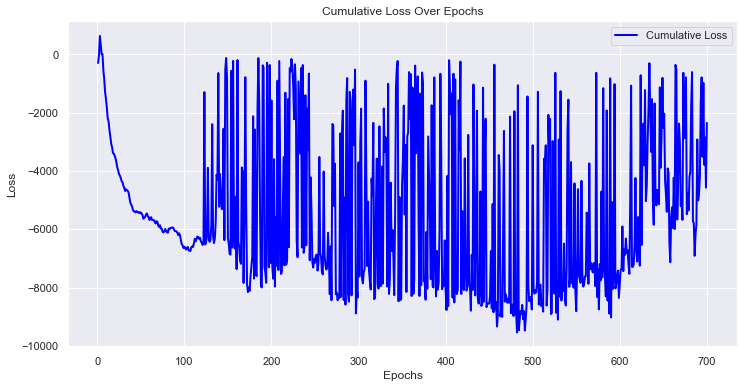

In [18]:
# Plot cumulative losses
plt.figure(figsize = (12, 6))
plt.plot(epochs_range, cumulative_losses, label = "Cumulative Loss", color = "blue", linewidth = 2)
plt.title("Cumulative Loss Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

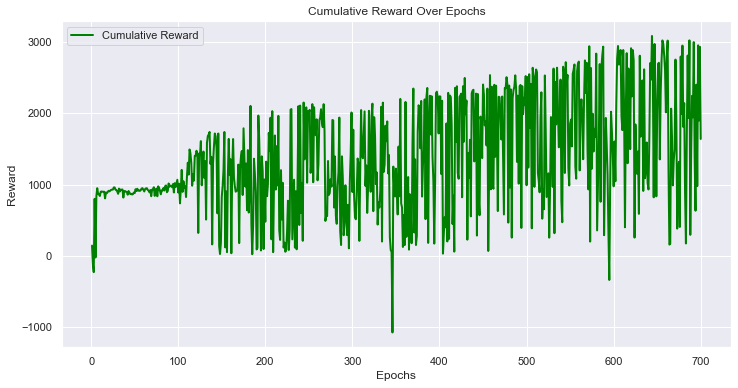

In [19]:
# Plot cumulative rewards
plt.figure(figsize = (12, 6))
plt.plot(epochs_range, cumulative_rewards, label = "Cumulative Reward", color = "green", linewidth = 2)
plt.title("Cumulative Reward Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Reward")
plt.legend()
plt.show()

In [20]:
# Smoothed plots using a rolling average for better trend visualization
window_size = 10
smoothed_losses = np.convolve(cumulative_losses, np.ones(window_size) / window_size, mode = "valid")
smoothed_rewards = np.convolve(cumulative_rewards, np.ones(window_size) / window_size, mode = "valid")

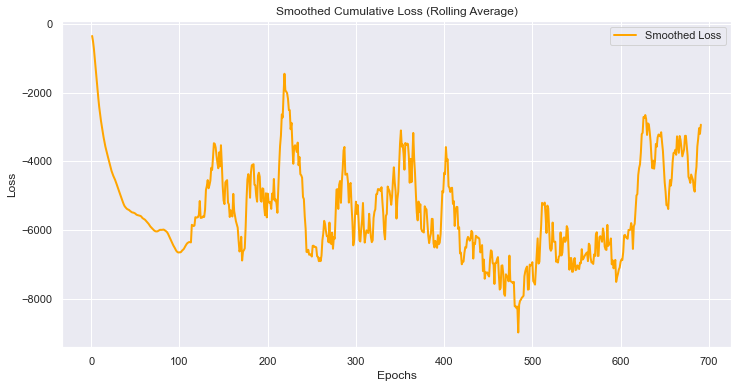

In [21]:
plt.figure(figsize = (12, 6))
plt.plot(range(1, len(smoothed_losses) + 1), smoothed_losses, label = "Smoothed Loss", color = "orange", linewidth = 2)
plt.title("Smoothed Cumulative Loss (Rolling Average)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

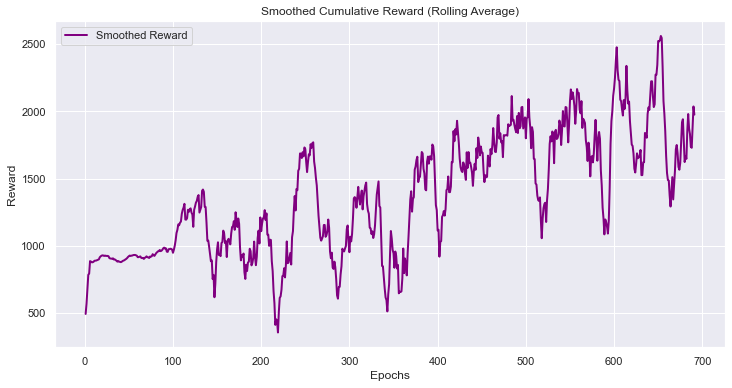

In [22]:
plt.figure(figsize = (12, 6))
plt.plot(range(1, len(smoothed_rewards) + 1), smoothed_rewards, label = "Smoothed Reward", color = "purple", linewidth = 2)
plt.title("Smoothed Cumulative Reward (Rolling Average)")
plt.xlabel("Epochs")
plt.ylabel("Reward")
plt.legend()
plt.show()

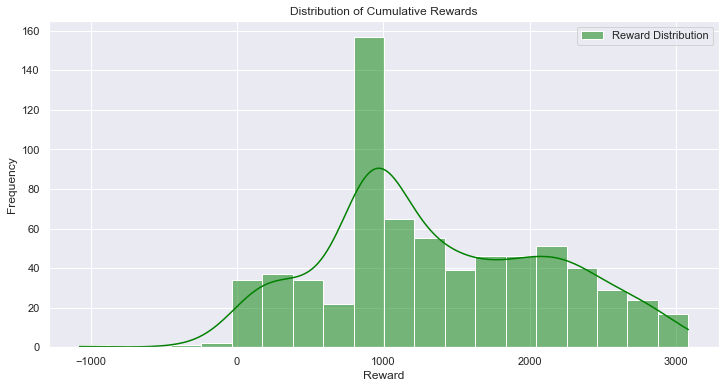

In [23]:
# Histogram of rewards for distribution visualization
plt.figure(figsize = (12, 6))
sns.histplot(cumulative_rewards, bins = 20, kde = True, color = "green", label = "Reward Distribution")
plt.title("Distribution of Cumulative Rewards")
plt.xlabel("Reward")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [24]:
# Bar plot for rewards at evaluation intervals
eval_indices = [i for i in range(len(cumulative_rewards) - 500, len(cumulative_rewards), eval_interval)]
eval_rewards = [cumulative_rewards[i] for i in eval_indices]

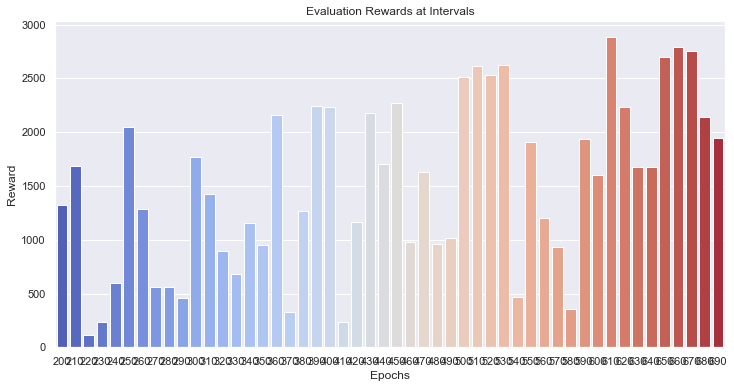

In [25]:
plt.figure(figsize = (12, 6))
sns.barplot(x = eval_indices, y = eval_rewards, palette = "coolwarm")
plt.title("Evaluation Rewards at Intervals")
plt.xlabel("Epochs")
plt.ylabel("Reward")
plt.show()